# The Hardy-Weinberg Principle

The Hardy-Weinberg principle describes the relationship between allele frequencies and genotype frequencies in a population under specific conditions.

For a diploid population with two alleles, A and a, at a single locus, the principle predicts that genotype frequencies follow a simple distribution determined by the allele frequencies:

$
f(AA)=p^2,\qquad f(Aa)=2pq,\qquad f(aa)=q^2
$

where $p$ and $q$ are the frequencies of alleles A and a, respectively, with $p+q=1$.

This notebook uses stochastic simulations to explore how these genotype proportions emerge through random mating, and how they behave across successive generations in a finite population.

## Objectives

The objectives of this notebook are to:

- Simulate a diploid population carrying two alleles at a single locus.
- Calculate allele and genotype frequencies from the population.
- Examine whether genotype frequencies match Hardy-Weinberg proportions after random mating.
- Follow allele and genotype frequencies across successive generations.
- Explore the effect of finite population size and random sampling on deviations from theoretical expectations.

## Model assumptions

The simulated population follows these assumptions:

* Diploid individuals.
* Two alleles: the locus has two possible alleles, A and a.
* Constant population size: the population contains $N$ individuals in every generation.
* Random mating: parents are sampled randomly from the population, independently and with replacement.
* Random segregation: each parent transmits one of its two alleles at random to its offspring.
* No mutation, no natural or sexual selection, no migration.


## Theoretical expectations

Let $p$ and $q$ denote the frequencies of alleles A and a, respectively:

$
p=f(A),\qquad q=f(a),\qquad p+q=1
$

Under random mating, the expected genotype frequencies in the next generation are:

$
\begin{aligned}
f(AA)&=p^2\\
f(Aa)&=2pq\\
f(aa)&=q^2
\end{aligned}
$

These are the **Hardy-Weinberg proportions**.

If the population initially does not follow these proportions, random mating leads to their establishment in one generation, provided the allele frequencies are taken from the parental population.

In an ideal infinite population, allele frequencies remain constant across generations in the absence of evolutionary forces. In a finite population, however, random sampling introduces fluctuations in allele frequencies through genetic drift.

Consequently, genotype frequencies are expected to remain close to Hardy-Weinberg proportions, but may deviate from them due to finite population sampling.

## Implementation

In [2]:
import matplotlib.pyplot as plt
import random
import numpy as np

In [3]:
def calculate_genotype_frequencies(population: np.ndarray) -> dict:
    """
    Calculate genotype frequencies in a diploid population.
    """
    population_size = len(population)

    number_of_AA = np.sum(np.all(population == [1, 1], axis=1))
    number_of_aa = np.sum(np.all(population == [0, 0], axis=1))
    number_of_Aa = population_size - number_of_AA - number_of_aa

    return {
        "AA": number_of_AA / population_size,
        "Aa": number_of_Aa / population_size,
        "aa": number_of_aa / population_size
    }

def calculate_allele_frequencies(population: np.ndarray) -> tuple:
    """
    Calculate allele frequencies in a diploid population.
    """
    genotype_frequencies = calculate_genotype_frequencies(population)

    p = genotype_frequencies["AA"] + 0.5 * genotype_frequencies["Aa"]
    q = genotype_frequencies["aa"] + 0.5 * genotype_frequencies["Aa"]

    return p, q

def calculate_hardy_weinberg_frequencies(p: float, q: float) -> dict:
    """
    Calculate expected genotype frequencies under Hardy-Weinberg equilibrium.
    """
    return {
        "AA": p**2,
        "Aa": 2 * p * q,
        "aa": q**2
    }

def next_generation(population: np.ndarray, rng) -> np.ndarray:
    """
    Generate offspring through random mating.
    """
    population_size = len(population)

    parent_indices = rng.integers(
        0, population_size, size=(population_size, 2)
    )

    allele_indices = rng.integers(0, 2, size=(population_size, 2))

    new_generation = population[parent_indices, allele_indices]

    return new_generation


In [4]:
seed = 42
rng = np.random.default_rng(seed)

In [7]:
# Parameters
N = 1000

p_AA = 0.5
p_aa = 0.3
p_Aa = 1 - p_AA - p_aa

In [8]:
# Population initialization
number_of_AA = int(round(p_AA * N))
number_of_aa = int(round(p_aa * N))
number_of_Aa = N - number_of_AA - number_of_aa

population = np.array(
    [[1, 1]] * number_of_AA
    + [[1, 0]] * number_of_Aa
    + [[0, 0]] * number_of_aa
)

rng.shuffle(population)

# Calculate observed frequencies
genotype_frequencies = calculate_genotype_frequencies(population)
p, q = calculate_allele_frequencies(population)

# Calculate expected Hardy-Weinberg frequencies
expected_frequencies = calculate_hardy_weinberg_frequencies(p, q)

print("--- Initial population ---")
print(f"Population size: N = {N}")

print("\nObserved genotype frequencies:")
for genotype, frequency in genotype_frequencies.items():
    print(f"  {genotype}: {frequency:.2f}")

print("\nAllele frequencies:")
print(f"  A: {p:.2f}")
print(f"  a: {q:.2f}")

print("\nExpected genotype frequencies under Hardy-Weinberg equilibrium:")
for genotype, frequency in expected_frequencies.items():
    print(f"  {genotype}: {frequency:.2f}")

print("\nThe initial population is not in Hardy-Weinberg proportions.")

--- Initial population ---
Population size: N = 1000

Observed genotype frequencies:
  AA: 0.50
  Aa: 0.20
  aa: 0.30

Allele frequencies:
  A: 0.60
  a: 0.40

Expected genotype frequencies under Hardy-Weinberg equilibrium:
  AA: 0.36
  Aa: 0.48
  aa: 0.16

The initial population is not in Hardy-Weinberg proportions.


In [9]:
def simulate_generations(initial_population: np.ndarray, generations: int, rng):

    population = initial_population.copy()

    genotype_history = []
    expected_genotype_history = []
    allele_history = []

    for generation in range(generations + 1):

        # Calculate observed genotype and allele frequencies
        genotype_frequencies = calculate_genotype_frequencies(population)
        p, q = calculate_allele_frequencies(population)

        # Calculate expected Hardy-Weinberg frequencies
        expected_frequencies = calculate_hardy_weinberg_frequencies(p, q)

        genotype_history.append([
            genotype_frequencies["AA"],
            genotype_frequencies["Aa"],
            genotype_frequencies["aa"]
        ])

        expected_genotype_history.append([
            expected_frequencies["AA"],
            expected_frequencies["Aa"],
            expected_frequencies["aa"]
        ])

        allele_history.append([p, q])

        # Generate the next population
        if generation < generations:
            population = next_generation(population, rng)

    return (
        np.array(genotype_history),
        np.array(expected_genotype_history),
        np.array(allele_history)
    )

In [10]:
# Simulation parameters
GENERATIONS = 20

In [11]:
genotype_history, expected_genotype_history, allele_history = (
    simulate_generations(population, GENERATIONS, rng)
)

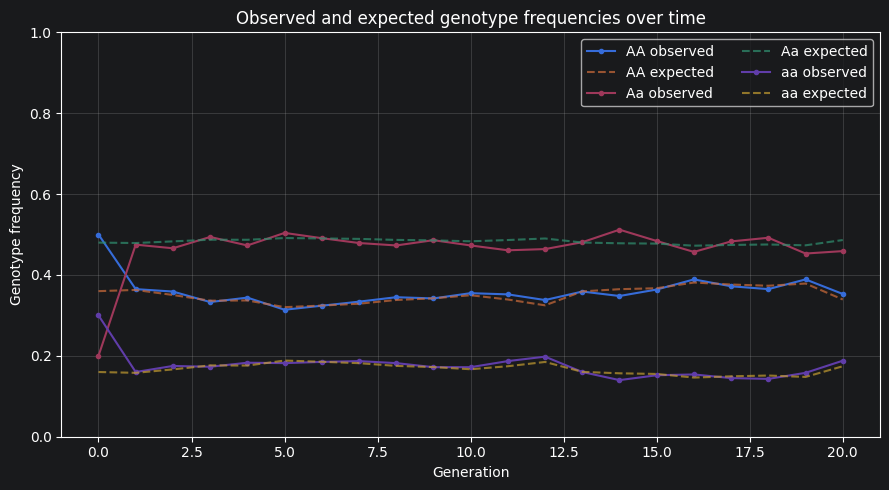

In [12]:
generations = np.arange(GENERATIONS + 1)

genotypes = ["AA", "Aa", "aa"]

fig, ax = plt.subplots(figsize=(9, 5))

for i, genotype in enumerate(genotypes):

    ax.plot(
        generations,
        genotype_history[:, i],
        marker="o",
        markersize=3,
        label=f"{genotype} observed"
    )

    ax.plot(
        generations,
        expected_genotype_history[:, i],
        linestyle="--",
        alpha=0.7,
        label=f"{genotype} expected"
    )

ax.set_xlabel("Generation")
ax.set_ylabel("Genotype frequency")
ax.set_title("Observed and expected genotype frequencies over time")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend(ncol=2)

plt.tight_layout()
plt.show()

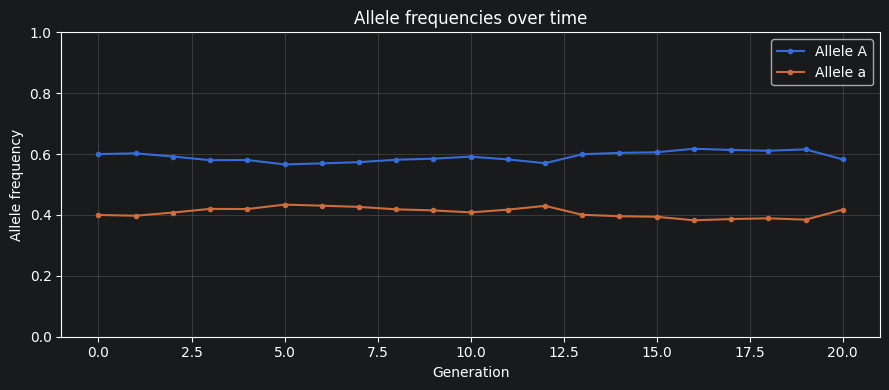

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    generations,
    allele_history[:, 0],
    marker="o",
    markersize=3,
    label="Allele A"
)

ax.plot(
    generations,
    allele_history[:, 1],
    marker="o",
    markersize=3,
    label="Allele a"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Allele frequency")
ax.set_title("Allele frequencies over time")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Conclusion

The simulation illustrates the establishment of Hardy-Weinberg proportions through random mating.

Initially, genotype frequencies differ from the theoretical proportions. After only one generation of random mating, the observed genotype frequencies become close to the expected theoretical values.

Small deviations remain because the population is finite and offspring are generated through random sampling.